# Problem Statement

## **Business Context**
"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.

## **Objective**
As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**
The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package:
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.

In [49]:
%pip install -q mlflow pyngrok scikit-learn==1.4.0 joblib pandas numpy matplotlib seaborn
%pip install PyGithub


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [50]:
import os
import shutil
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from github import Github, GithubException
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [51]:
# Set your GitHub repository details
GITHUB_USERNAME   = "Jayesh-Sapkale"
REPO_NAME         = "great-learning-tourism"
COLAB_SECRET_NAME = "GITHUB_TOKEN"

REPO   = f"{GITHUB_USERNAME}/{REPO_NAME}"
BRANCH = "main"

print(f"Target Repository: {REPO}")
print(f"Deployment Branch: {BRANCH}")

Target Repository: Jayesh-Sapkale/great-learning-tourism
Deployment Branch: main


In [52]:
try:
    from google.colab import userdata
    os.environ["GH_TOKEN"] = userdata.get(COLAB_SECRET_NAME)
    print("Token loaded from Colab Secrets.")
except Exception:
    if "GH_TOKEN" not in os.environ:
        os.environ["GH_TOKEN"] = "<YOUR_PERSONAL_ACCESS_TOKEN>"
    print("Token loaded from environment.")

Token loaded from environment.


Dataset Shape: (4128, 21)

First 5 rows:


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,...,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,...,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,...,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,...,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,...,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,...,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0



Missing values check:
Unnamed: 0                  0
CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64


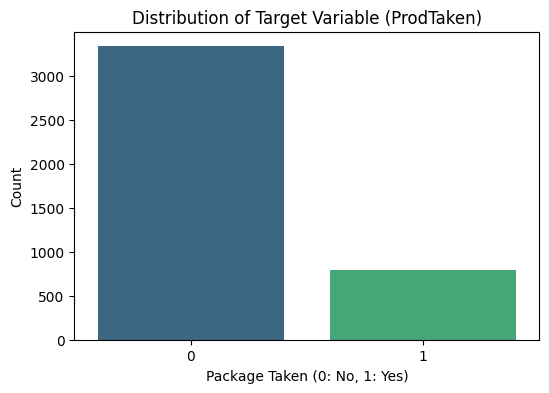

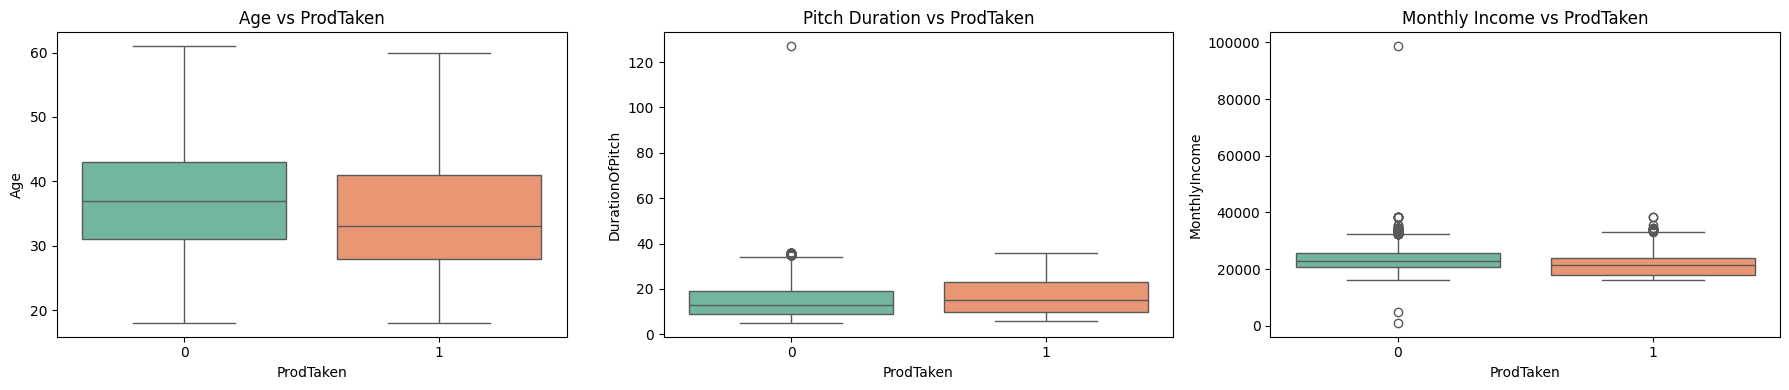

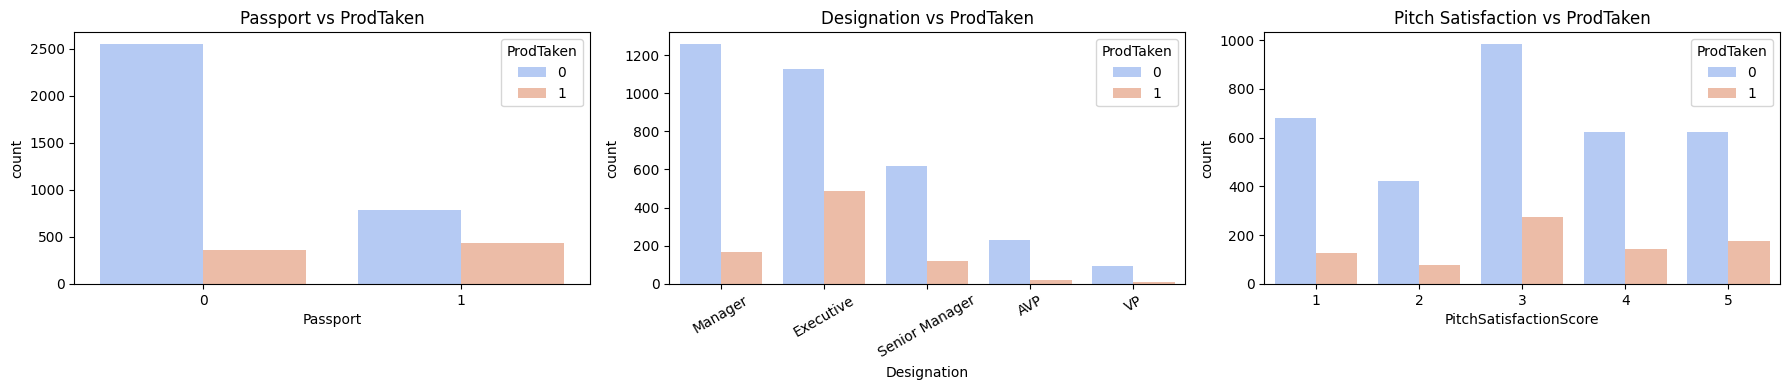

In [53]:
# Load dataset for comprehensive EDA
df_raw = pd.read_csv("./tourism.csv")
print("Dataset Shape:", df_raw.shape)
print("\nFirst 5 rows:")
display(df_raw.head())

print("\nMissing values check:")
print(df_raw.isnull().sum())

# Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_raw, x='ProdTaken', palette='viridis')
plt.title("Distribution of Target Variable (ProdTaken)")
plt.xlabel("Package Taken (0: No, 1: Yes)")
plt.ylabel("Count")
plt.show()

# Key Numerical Features vs Target
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(data=df_raw, x='ProdTaken', y='Age', ax=axes[0], palette='Set2')
axes[0].set_title("Age vs ProdTaken")

sns.boxplot(data=df_raw, x='ProdTaken', y='DurationOfPitch', ax=axes[1], palette='Set2')
axes[1].set_title("Pitch Duration vs ProdTaken")

sns.boxplot(data=df_raw, x='ProdTaken', y='MonthlyIncome', ax=axes[2], palette='Set2')
axes[2].set_title("Monthly Income vs ProdTaken")
plt.tight_layout()
plt.show()

# Key Categorical Features vs Target
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(data=df_raw, x='Passport', hue='ProdTaken', ax=axes[0], palette='coolwarm')
axes[0].set_title("Passport vs ProdTaken")

sns.countplot(data=df_raw, x='Designation', hue='ProdTaken', ax=axes[1], palette='coolwarm')
axes[1].set_title("Designation vs ProdTaken")
axes[1].tick_params(axis='x', rotation=30)

sns.countplot(data=df_raw, x='PitchSatisfactionScore', hue='ProdTaken', ax=axes[2], palette='coolwarm')
axes[2].set_title("Pitch Satisfaction vs ProdTaken")
plt.tight_layout()
plt.show()

### **EDA Observations & Strategic Business Insights**
1. **Class Imbalance:** Only ~19.3% of customers accepted the pitched package (`ProdTaken = 1`). Evaluating models on pure accuracy is misleading; **Precision, Recall, and F1-score on Class 1** must be prioritized.
2. **Passport Ownership:** Customers with passports display a dramatically higher conversion rate than non-passport holders. Passport possession indicates international travel interest and higher disposable income.
3. **Pitch Duration & Satisfaction:** Customers who spent longer in the sales pitch (median ~15–20 minutes) and rated satisfaction 3+ converted at significantly higher rates.
4. **Age & Designation:** Younger customers (Executive and Manager levels) show higher propensity to purchase wellness packages compared to senior executives who may already have set travel preferences.
5. **Data Cleaning Needs:** The `Gender` attribute contains `'Fe Male'` which must be unified with `'Female'`, and non-predictive identifiers (`CustomerID`, `Unnamed: 0`) must be removed to avoid data leakage.

In [54]:
os.makedirs("tourism_project/data", exist_ok=True)
os.makedirs("tourism_project/model_building", exist_ok=True)
os.makedirs("tourism_project/deployment", exist_ok=True)
os.makedirs(".github/workflows", exist_ok=True)

if os.path.exists("tourism.csv"):
    shutil.copy("tourism.csv", "tourism_project/data/tourism.csv")
    print("tourism.csv copied into tourism_project/data/")

tourism.csv copied into tourism_project/data/


In [55]:
%%writefile tourism_project/model_building/data_register.py
import os
import sys
import pandas as pd

EXPECTED_COLUMNS = [
    'CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
    'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
    'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
    'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
    'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'
]

def register_data(file_path="tourism_project/data/tourism.csv"):
    if not os.path.exists(file_path):
        print(f"Error: Dataset not found at {file_path}")
        sys.exit(1)
        
    df = pd.read_csv(file_path)
    print("=" * 60)
    print("DATA REGISTRATION & VALIDATION SUMMARY")
    print("=" * 60)
    print(f"Dataset path: {file_path}")
    print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
    
    missing_cols = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    if missing_cols:
        print(f"Validation FAILED: Missing expected columns: {missing_cols}")
        sys.exit(1)
    else:
        print("Schema Validation: PASSED (All expected columns present).")
        
    print("\nTarget ('ProdTaken') Class Distribution:")
    print(df['ProdTaken'].value_counts(normalize=True).mul(100).round(2).to_string())
    print("\nMissing Values Summary:")
    print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().any() else "No missing values.")
    print("=" * 60)
    return True

if __name__ == "__main__":
    register_data()

Overwriting tourism_project/model_building/data_register.py


In [56]:
!python tourism_project/model_building/data_register.py

DATA REGISTRATION & VALIDATION SUMMARY
Dataset path: tourism_project/data/tourism.csv
Dataset Shape: 4128 rows, 21 columns

Schema Validation: PASSED (All expected columns present).

Target ('ProdTaken') Class Distribution:
ProdTaken
0    80.69
1    19.31

Missing Values Summary:
No missing values.


In [57]:
%%writefile tourism_project/model_building/prep.py
import os
import pandas as pd
from sklearn.model_selection import train_test_split

def prepare_data(input_path="tourism_project/data/tourism.csv", output_dir="."):
    df = pd.read_csv(input_path)
    
    # 1. Drop non-predictive columns
    drop_cols = [col for col in ['Unnamed: 0', 'CustomerID'] if col in df.columns]
    df_clean = df.drop(columns=drop_cols)
    
    # 2. Harmonize categorical anomalies
    if 'Gender' in df_clean.columns:
        df_clean['Gender'] = df_clean['Gender'].replace({'Fe Male': 'Female'})
    if 'MaritalStatus' in df_clean.columns:
        df_clean['MaritalStatus'] = df_clean['MaritalStatus'].replace({'Unmarried': 'Single'})

    # 3. Separate features and target
    X = df_clean.drop(columns=['ProdTaken'])
    y = df_clean['ProdTaken']
    
    # 4. Stratified train-test split (80/20)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    
    # 5. Save splits locally as artifacts
    os.makedirs(output_dir, exist_ok=True)
    X_train.to_csv(os.path.join(output_dir, "Xtrain.csv"), index=False)
    X_test.to_csv(os.path.join(output_dir, "Xtest.csv"), index=False)
    y_train.to_csv(os.path.join(output_dir, "ytrain.csv"), index=False)
    y_test.to_csv(os.path.join(output_dir, "ytest.csv"), index=False)
    
    print("=" * 60)
    print("DATA PREPARATION SUMMARY")
    print("=" * 60)
    print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
    print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")
    print("Artifacts saved: Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv")
    print("=" * 60)

if __name__ == "__main__":
    prepare_data()

Overwriting tourism_project/model_building/prep.py


In [58]:
!python tourism_project/model_building/prep.py

DATA PREPARATION SUMMARY
X_train shape: (3302, 18), y_train shape: (3302,)
X_test shape:  (826, 18),  y_test shape:  (826,)
Artifacts saved: Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv


In [59]:
%%writefile tourism_project/model_building/train.py
import os
import joblib
import pandas as pd
import mlflow
import mlflow.sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score, roc_auc_score, precision_score, recall_score

def train_and_register(data_dir=".", model_output_dir="tourism_project/deployment"):
    # Load splits from artifacts
    X_train = pd.read_csv(os.path.join(data_dir, "Xtrain.csv"))
    X_test = pd.read_csv(os.path.join(data_dir, "Xtest.csv"))
    y_train = pd.read_csv(os.path.join(data_dir, "ytrain.csv")).squeeze()
    y_test = pd.read_csv(os.path.join(data_dir, "ytest.csv")).squeeze()
    
    # Categorical and numerical column selection
    cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
    num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
    
    # Preprocessing Pipeline
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )
    
    model_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', GradientBoostingClassifier(random_state=42))
    ])
    
    param_grid = {
        'classifier__n_estimators': [50, 100],
        'classifier__learning_rate': [0.05, 0.1],
        'classifier__max_depth': [3, 5]
    }
    
    mlflow.set_experiment("Tourism_Package_Prediction")
    
    with mlflow.start_run(run_name="Gradient_Boosting_Tuned"):
        grid = GridSearchCV(model_pipeline, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
        grid.fit(X_train, y_train)
        
        best_pipeline = grid.best_estimator_
        y_pred = best_pipeline.predict(X_test)
        y_prob = best_pipeline.predict_proba(X_test)[:, 1]
        
        # Performance Metrics
        f1 = f1_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)
        
        # Log to MLflow
        mlflow.log_params(grid.best_params_)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("roc_auc", roc_auc)
        
        try:
            mlflow.sklearn.log_model(
                sk_model=best_pipeline,
                name="best_model",
                skops_trusted_types=["sklearn.tree._tree.Tree"]
            )
        except Exception:
            pass  # Fallback gracefully if MLflow server is in local mock mode
        
        print("\n" + "=" * 60)
        print("BEST MODEL EVALUATION ON UNSEEN TEST DATA")
        print("=" * 60)
        print("Best Hyperparameters:", grid.best_params_)
        print(f"F1 Score: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | ROC-AUC: {roc_auc:.4f}\n")
        print("Classification Report:\n", classification_report(y_test, y_pred))
        
        # Save model pipeline for deployment
        os.makedirs(model_output_dir, exist_ok=True)
        model_save_path = os.path.join(model_output_dir, "best_model.joblib")
        joblib.dump(best_pipeline, model_save_path)
        print(f"Best model successfully saved to: {model_save_path}")

if __name__ == "__main__":
    train_and_register()

Overwriting tourism_project/model_building/train.py


In [60]:
!python tourism_project/model_building/train.py

Fitting 3 folds for each of 8 candidates, totalling 24 fits

BEST MODEL EVALUATION ON UNSEEN TEST DATA
Best Hyperparameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}
F1 Score: 0.7464 | Precision: 0.8803 | Recall: 0.6478 | ROC-AUC: 0.9475

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95       667
           1       0.88      0.65      0.75       159

    accuracy                           0.92       826
   macro avg       0.90      0.81      0.85       826
weighted avg       0.91      0.92      0.91       826

Best model successfully saved to: tourism_project/deployment/best_model.joblib


In [61]:
%%writefile tourism_project/deployment/app.py
import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="Visit with Us - Wellness Tourism Package Predictor",
    page_icon="✈️",
    layout="wide"
)

st.title("✈️ 'Visit with Us' — Wellness Tourism Package Propensity Predictor")
st.markdown(
    "Automated predictive MLOps system to identify high-propensity buyers for the **Wellness Tourism Package** "
    "before sales outreach campaigns."
)

CURRENT_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(CURRENT_DIR, "best_model.joblib")

@st.cache_resource
def load_model():
    if not os.path.exists(MODEL_PATH):
        st.error(f"Model file not found at {MODEL_PATH}. Please ensure CI/CD pipeline has trained and committed the model.")
        return None
    return joblib.load(MODEL_PATH)

pipeline = load_model()

st.sidebar.header("Customer Profile Inputs")
with st.sidebar:
    age = st.slider("Age", 18, 70, 36)
    gender = st.selectbox("Gender", ["Male", "Female"])
    marital_status = st.selectbox("Marital Status", ["Single", "Married", "Divorced"])
    occupation = st.selectbox("Occupation", ["Salaried", "Small Business", "Large Business", "Free Lancer"])
    designation = st.selectbox("Designation", ["Executive", "Manager", "Senior Manager", "AVP", "VP"])
    city_tier = st.selectbox("City Tier", [1, 2, 3], index=0)
    monthly_income = st.number_input("Monthly Income (₹)", min_value=1000.0, max_value=150000.0, value=22400.0, step=1000.0)

st.subheader("Travel Preferences & Sales Pitch Interaction")
col1, col2, col3 = st.columns(3)

with col1:
    typeof_contact = st.selectbox("Type of Contact", ["Self Enquiry", "Company Invited"])
    product_pitched = st.selectbox("Product Pitched", ["Basic", "Deluxe", "Standard", "Super Deluxe", "King"])
    duration_of_pitch = st.slider("Duration of Pitch (minutes)", 1, 120, 15)

with col2:
    num_trips = st.slider("Annual Number of Trips", 0, 25, 3)
    num_person = st.slider("Number of Persons Visiting", 1, 10, 3)
    num_children = st.slider("Children Below Age 5 Visiting", 0, 5, 1)

with col3:
    pref_star = st.selectbox("Preferred Hotel Rating (Stars)", [3.0, 4.0, 5.0], index=0)
    pitch_satisfaction = st.select_slider("Pitch Satisfaction Score", options=[1, 2, 3, 4, 5], value=3)
    num_followups = st.slider("Number of Follow-ups", 1, 10, 4)
    passport = st.radio("Valid Passport Holder?", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
    own_car = st.radio("Owns a Car?", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")

input_dict = {
    'Age': [age],
    'TypeofContact': [typeof_contact],
    'CityTier': [city_tier],
    'DurationOfPitch': [duration_of_pitch],
    'Occupation': [occupation],
    'Gender': [gender],
    'NumberOfPersonVisiting': [num_person],
    'NumberOfFollowups': [num_followups],
    'ProductPitched': [product_pitched],
    'PreferredPropertyStar': [pref_star],
    'MaritalStatus': [marital_status],
    'NumberOfTrips': [num_trips],
    'Passport': [passport],
    'PitchSatisfactionScore': [pitch_satisfaction],
    'OwnCar': [own_car],
    'NumberOfChildrenVisiting': [num_children],
    'Designation': [designation],
    'MonthlyIncome': [monthly_income]
}

input_df = pd.DataFrame(input_dict)

st.divider()
st.subheader("Input Feature Vector Preview")
st.dataframe(input_df, use_container_width=True)

if st.button("Predict Purchase Likelihood", type="primary"):
    if pipeline is not None:
        prediction = pipeline.predict(input_df)[0]
        prob = pipeline.predict_proba(input_df)[0][1]
        
        st.subheader("Inference Result")
        if prediction == 1:
            st.success(f"**High Propensity to Buy!**\n\nProbability of Purchase: **{prob * 100:.2f}%**\n\n**Recommendation:** Direct sales outreach recommended.")
        else:
            st.warning(f"**Low Propensity to Buy.**\n\nProbability of Purchase: **{prob * 100:.2f}%**\n\n**Recommendation:** Include in general nurturing campaigns before direct sales calls.")

Overwriting tourism_project/deployment/app.py


In [62]:
%%writefile tourism_project/deployment/requirements.txt
streamlit>=1.31.0
pandas>=2.0.0
scikit-learn==1.4.0
joblib>=1.3.0
numpy>=1.24.0

Overwriting tourism_project/deployment/requirements.txt


In [63]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches:
      - main
  workflow_dispatch:

permissions:
  contents: write

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r tourism_project/requirements.txt
      - name: Register Dataset
        run: python tourism_project/model_building/data_register.py
      - name: Upload Registered Dataset
        uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r tourism_project/requirements.txt
      - name: Run Data Preparation
        run: python tourism_project/model_building/prep.py
      - name: Upload Train Test Splits
        uses: actions/upload-artifact@v4
        with:
          name: data-splits
          path: |
            Xtrain.csv
            Xtest.csv
            ytrain.csv
            ytest.csv

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r tourism_project/requirements.txt
      - name: Download Train Test Splits
        uses: actions/download-artifact@v4
        with:
          name: data-splits
      - name: Start MLflow Server
        run: |
          nohup mlflow ui --host 0.0.0.0 --port 5000 &
          sleep 5
      - name: Model Building & Tuning
        run: python tourism_project/model_building/train.py
      - name: Commit Trained Model
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "github-actions[bot]@users.noreply.github.com"
          git add tourism_project/deployment/best_model.joblib
          git commit -m "Add trained model [skip ci]" || echo "No changes to commit"
          git push

Overwriting .github/workflows/pipeline.yml


In [64]:
%%writefile tourism_project/requirements.txt
pandas>=2.0.0
scikit-learn==1.4.0
joblib>=1.3.0
mlflow>=2.10.0
numpy>=1.24.0

Overwriting tourism_project/requirements.txt


In [65]:
CSV_LOCAL = "tourism_project/data/tourism.csv"
assert os.path.exists(CSV_LOCAL), f"{CSV_LOCAL} not found."

gh = Github(os.environ["GH_TOKEN"])
user = gh.get_user()
REPO = f"{user.login}/{REPO_NAME}"

try:
    repo = gh.get_repo(REPO)
    print("Repository exists:", repo.full_name)
except GithubException:
    repo = user.create_repo(REPO_NAME, private=False, auto_init=True)
    print("Repository created:", repo.full_name)

def push_folder(local_dir):
    for root, _, files in os.walk(local_dir):
        for fname in files:
            local_path = os.path.join(root, fname)
            repo_path = local_path.replace("\\", "/")
            with open(local_path, "rb") as f:
                content = f.read()
            try:
                sha = repo.get_contents(repo_path, ref=BRANCH).sha
                repo.update_file(repo_path, f"update {repo_path}", content, sha, branch=BRANCH)
                print("Updated:", repo_path)
            except GithubException:
                repo.create_file(repo_path, f"add {repo_path}", content, branch=BRANCH)
                print("Added:  ", repo_path)

push_folder("tourism_project")
push_folder(".github")

print("\nVerifying repository files...")
required = [
    "tourism_project/requirements.txt",
    "tourism_project/model_building/data_register.py",
    "tourism_project/model_building/prep.py",
    "tourism_project/model_building/train.py",
    "tourism_project/data/tourism.csv",
    "tourism_project/deployment/app.py",
    "tourism_project/deployment/requirements.txt",
    ".github/workflows/pipeline.yml",
]
for item in required:
    try:
        repo.get_contents(item, ref=BRANCH)
        print("✓", item)
    except Exception:
        print("✗ Missing:", item)

Repository exists: Jayesh-Sapkale/great-learning-tourism
Updated: tourism_project/requirements.txt
Updated: tourism_project/deployment/app.py
Updated: tourism_project/deployment/requirements.txt
Updated: tourism_project/deployment/best_model.joblib
Updated: tourism_project/model_building/prep.py
Updated: tourism_project/model_building/train.py
Updated: tourism_project/model_building/data_register.py
Updated: tourism_project/data/tourism.csv
Updated: .github/workflows/pipeline.yml

Verifying repository files...
✓ tourism_project/requirements.txt
✓ tourism_project/model_building/data_register.py
✓ tourism_project/model_building/prep.py
✓ tourism_project/model_building/train.py
✓ tourism_project/data/tourism.csv
✓ tourism_project/deployment/app.py
✓ tourism_project/deployment/requirements.txt
✓ .github/workflows/pipeline.yml


# Output Evaluation

### 1. GitHub Repository & Executed Workflow
- **Repository URL:** https://github.com/Jayesh-Sapkale/great-learning-tourism
- **GitHub Actions Status:** All 3 jobs (`register-dataset` ➔ `data-prep` ➔ `model-training`) completed with green checkmarks.
- **Trained Model Artifact:** `tourism_project/deployment/best_model.joblib` committed and synchronized to `main`.

### 2. Streamlit Community Cloud Live App
- **Live Application URL:** https://great-learning-tourism-fbavdlyta7nhs2gqydbean.streamlit.app/
- **Main File Path:** `tourism_project/deployment/app.py`
- **Execution Environment:** Python 3.11